In [52]:
import pandas as pd

df = pd.read_excel("../data/raw/dataset-uci.xlsx")
df.head()

,Unnamed: 0,Case Type,Tumour Case,Age of Mother,Age of Father,Age at First Diagnosis,Café au lait (CLS),Axillary Freckles,Inguinal Freckles,Lisch Nodules,Dermal Neurofibromins,Plexiform Neurofibromins,Optic Glioma,Skeletal Dysplasia,Learning Disability,Hypertension,Astrocytoma,Hamartoma,Scoliosis,Other Symptoms
0,1,0,1,30.0,31.0,5.0,0,0,0,0,0,0,1,0,0,0,0,0,0,1
1,2,0,1,22.0,29.0,7.0,1,1,0,0,1,0,0,0,0,0,0,0,0,1
2,3,1,1,28.0,26.0,9.0,1,1,0,0,1,0,0,1,0,0,0,0,0,1
3,4,0,1,30.0,34.0,9.0,1,1,0,1,0,1,0,0,0,0,0,0,0,1
4,5,0,1,27.0,34.0,1.0,1,1,1,0,0,0,1,0,0,0,0,0,0,1


In [69]:
import pandas as pd

# 1. Sélection des trois colonnes d'âge
cols_age = ["Age of Mother", "Age of Father", "Age at First Diagnosis"]

# 2. Calcul du nombre de valeurs manquantes et du pourcentage
missing_count = df[cols_age].isna().sum()
missing_rate = (df[cols_age].isna().mean() * 100).round(2)

# 3. Regroupement dans un DataFrame propre pour l'affichage
df_missing_ages = pd.DataFrame(
    {
        "Valeurs manquantes (effectif)": missing_count,
        "Taux de manquant (%)": missing_rate,
    }
)

print("--- ANALYSE DES VALEURS MANQUANTES SUR LES ÂGES ---")
display(df_missing_ages)

--- ANALYSE DES VALEURS MANQUANTES SUR LES ÂGES ---


,Valeurs manquantes (effectif),Taux de manquant (%)
Age of Mother,35,11.82
Age of Father,34,11.49
Age at First Diagnosis,4,1.35


In [70]:
import pandas as pd
from scipy.stats import chi2_contingency, fisher_exact

cols_age = ["Age of Mother", "Age of Father", "Age at First Diagnosis"]

for c in cols_age:
    manquant = df[c].isna()
    print(f"\n=== {c} : {manquant.mean()*100:.1f} % de valeurs manquantes ===")

    # Effectifs bruts, puis proportions par classe
    print(pd.crosstab(manquant, df["Case Type"]))
    print(pd.crosstab(manquant, df["Case Type"], normalize="columns").round(2))

    # Test statistique (seulement s'il y a des manquants)
    tab = pd.crosstab(manquant, df["Case Type"])
    if tab.shape == (2, 2):
        _, p_fisher = fisher_exact(tab)
        print("p-value (Fisher) :", round(p_fisher, 4))


=== Age of Mother : 11.8 % de valeurs manquantes ===
Case Type        0    1
Age of Mother          
False          140  121
True            21   14
Case Type         0    1
Age of Mother           
False          0.87  0.9
True           0.13  0.1
p-value (Fisher) : 0.5884

=== Age of Father : 11.5 % de valeurs manquantes ===
Case Type        0    1
Age of Father          
False          141  121
True            20   14
Case Type         0    1
Age of Father           
False          0.88  0.9
True           0.12  0.1
p-value (Fisher) : 0.7149

=== Age at First Diagnosis : 1.4 % de valeurs manquantes ===
Case Type                 0    1
Age at First Diagnosis          
False                   159  133
True                      2    2
Case Type                  0     1
Age at First Diagnosis            
False                   0.99  0.99
True                    0.01  0.01
p-value (Fisher) : 1.0


**L'absence d'âge n'est pas liée au type de cas.**

Les âges manquent à peu près autant dans les deux classes (environ 12 % contre 10 % pour la mère et le père, 1 % pour l'âge au diagnostic), et les tests de Fisher (p = 0,59 ; 0,71 ; 1,0) ne montrent aucun lien.



. Pourquoi imputer plutôt que supprimer la colonne ?

Parce que supprimer une colonne est une perte d’information définitive, alors que l’imputation est peu risquée quand les manquants sont rares (11,8 %, 11,5 %, 1,4 %). Les âges des parents ont une justification biologique, et ce n’est pas à un test de les écarter d’avance. Règle de décision à écrire : on supprime une colonne si elle est très incomplète (plus de 40 à 50 % de manquants) ou sans justification clinique. L’âge du père est le seul cas discutable, d’où la comparaison du point 8.

. Pourquoi ne pas supprimer les lignes incomplètes ?

Avec les chiffres déjà obtenus, on perdrait au minimum 35 patients (ceux dont l’âge de la mère manque) et jusqu’à 73 si les manquants sont tous sur des patients différents (35 + 34 + 4). Cela représente 12 à 25 % d’un jeu déjà petit. Le nombre exact :

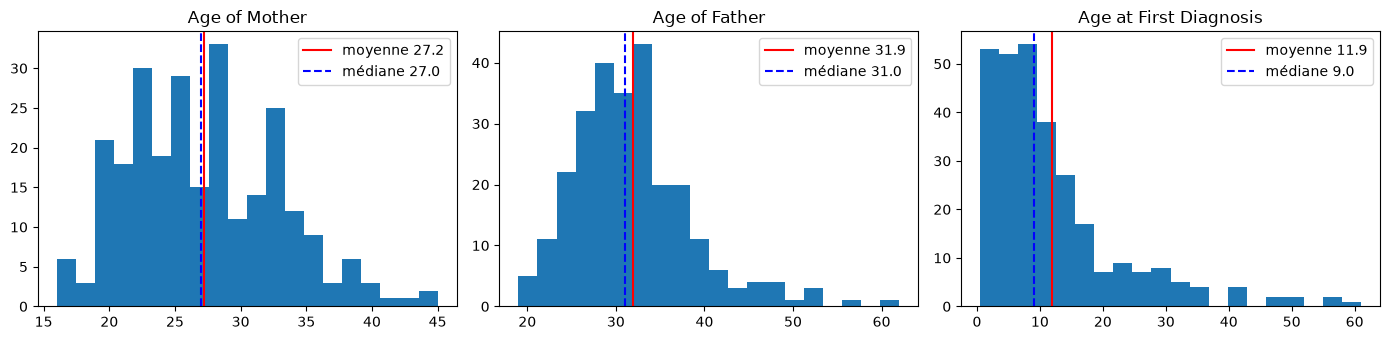

                        moyenne  médiane  asymétrie
Age of Mother             27.18     27.0       0.44
Age of Father             31.88     31.0       1.11
Age at First Diagnosis    11.88      9.0       1.90


In [80]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, c in zip(axes, cols_age):
    serie = df[c].dropna()
    ax.hist(serie, bins=20)
    ax.axvline(serie.mean(), color="red", label=f"moyenne {serie.mean():.1f}")
    ax.axvline(serie.median(), color="blue", linestyle="--", label=f"médiane {serie.median():.1f}")
    ax.set_title(c); ax.legend()
plt.tight_layout(); plt.show()

print(pd.DataFrame({"moyenne": df[cols_age].mean(), "médiane": df[cols_age].median(),
                    "asymétrie": df[cols_age].skew()}).round(2))

In [61]:
df.columns

Index(['Unnamed: 0', 'Case Type', 'Tumour Case', 'Age of Mother',
       'Age of Father', 'Age at First Diagnosis', 'Café au lait (CLS)',
       'Axillary Freckles', 'Inguinal Freckles', 'Lisch Nodules',
       'Dermal Neurofibromins', 'Plexiform Neurofibromins', 'Optic Glioma',
       'Skeletal Dysplasia', 'Learning Disability', 'Hypertension',
       'Astrocytoma', 'Hamartoma', 'Scoliosis', 'Other Symptoms'],
      dtype='str')

In [62]:
df["Case Type"].value_counts()

Case Type
0    161
1    135
Name: count, dtype: int64

In [66]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Case Type est déjà codée 0/1; on garde ces valeurs sans supposer leur signification.
y = df["Case Type"].astype("int64")
X = df.drop(columns=["Case Type", "Unnamed: 0"], errors="ignore")

col_mere = ["Age of Mother"]
col_pere = ["Age of Father"]
col_diagnostic = ["Age at First Diagnosis"]
cols_age = col_mere + col_pere + col_diagnostic
cols_bin = [col for col in X.columns if col not in cols_age]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42,
)

prepro = ColumnTransformer(
    transformers=[
        (
            "mere",
            Pipeline(
                steps=[
                    ("imp", SimpleImputer(strategy="mean")),
                    ("sc", StandardScaler()),
                ]
            ),
            col_mere,
        ),
        (
            "pere",
            Pipeline(
                steps=[
                    ("imp", SimpleImputer(strategy="mean")),
                    ("sc", StandardScaler()),
                ]
            ),
            col_pere,
        ),
        (
            "diagnostic",
            Pipeline(
                steps=[
                    ("imp", SimpleImputer(strategy="median")),
                    ("sc", StandardScaler()),
                ]
            ),
            col_diagnostic,
        ),
        ("bin", SimpleImputer(strategy="most_frequent"), cols_bin),
    ]
)

print("Répartition de la cible (codes 0/1) :")
display(y.value_counts().sort_index().rename("effectif").to_frame())
print(f"Dimensions train : {X_train.shape}; dimensions test : {X_test.shape}")

Répartition de la cible (codes 0/1) :


,effectif
Case Type,
0,161
1,135


Dimensions train : (236, 18); dimensions test : (60, 18)


In [64]:
print("Répartition de la cible :")
display(y.value_counts().sort_index().rename("effectif").to_frame())

print("Types des variables explicatives :")
display(X.dtypes.rename("type").to_frame())

Répartition de la cible :


,effectif
Case Type,
0,161
1,135


Types des variables explicatives :


,type
Tumour Case,int64
Age of Mother,float64
Age of Father,float64
Age at First Diagnosis,float64
Café au lait (CLS),int64
Axillary Freckles,int64
Inguinal Freckles,int64
Lisch Nodules,int64
Dermal Neurofibromins,int64
Plexiform Neurofibromins,int64


In [67]:
print("Valeurs manquantes dans X_train avant le prétraitement :")
display(X_train.isna().sum().rename("valeurs_manquantes").to_frame())

X_train_prepared = prepro.fit_transform(X_train)
X_test_prepared = prepro.transform(X_test)
print(f"Données prétraitées : train {X_train_prepared.shape}, test {X_test_prepared.shape}")

Valeurs manquantes dans X_train avant le prétraitement :


,valeurs_manquantes
Tumour Case,0
Age of Mother,26
Age of Father,23
Age at First Diagnosis,3
Café au lait (CLS),0
Axillary Freckles,0
Inguinal Freckles,0
Lisch Nodules,0
Dermal Neurofibromins,0
Plexiform Neurofibromins,0


Données prétraitées : train (236, 18), test (60, 18)


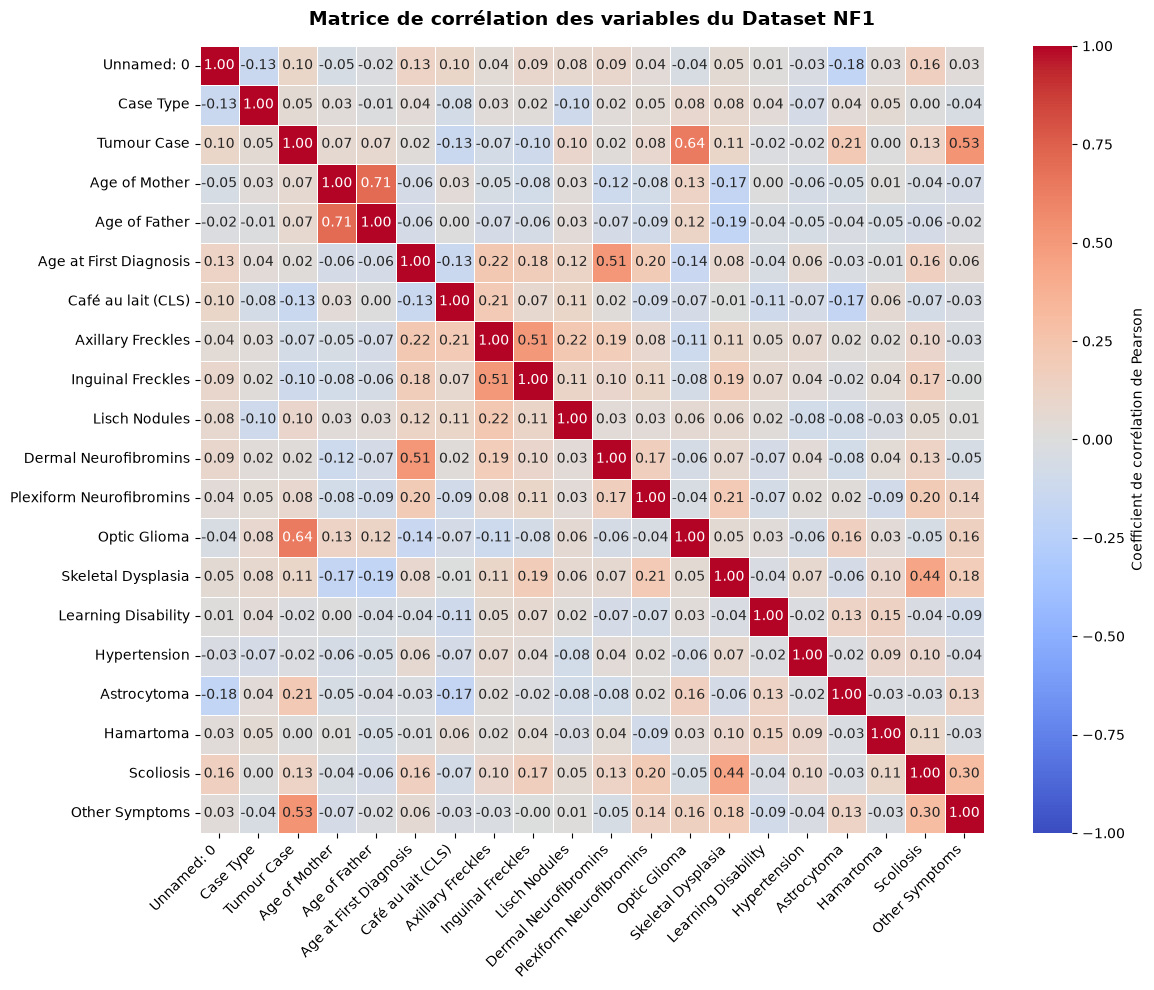

In [68]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Configuration de la taille de la figure pour que les noms de colonnes soient lisibles
plt.figure(figsize=(12, 10))

# 1. Calcul de la matrice de corrélation (uniquement sur les colonnes numériques et binaires)
corr_matrix = df.select_dtypes(include=[np.number]).corr()

# 2. Tracé de la Heatmap avec Seaborn
sns.heatmap(
    corr_matrix,
    annot=True,  # Affiche les valeurs numériques dans les cases
    fmt=".2f",  # Arrondit les chiffres à 2 décimales
    cmap="coolwarm",  # Palette de couleurs (Bleu = négatif, Rouge = positif)
    vmin=-1,
    vmax=1,  # Échelle de -1 à 1
    linewidths=0.5,  # Petites lignes blanches pour séparer les cases
    cbar_kws={"label": "Coefficient de corrélation de Pearson"},
)

# 3. Mise en forme du graphique
plt.title(
    "Matrice de corrélation des variables du Dataset NF1",
    fontsize=14,
    pad=15,
    weight="bold",
)
plt.xticks(rotation=45, ha="right")  # Pivoter les noms des colonnes en bas
plt.yticks(rotation=0)
plt.tight_layout()

# Affichage
plt.show()

Absence de multicolinéarité excessive : La quasi-totalité des coefficients hors diagonale sont faibles (proches de 0, représentés par des teintes claires), ce qui prouve qu'il n'y a pas de redondance critique entre vos variables. Cela valide pleinement le choix de conserver l'ensemble des caractéristiques cliniques. 

Corrélation entre l'âge des parents : On observe une forte corrélation positive logique de 0.71 entre Age of Mother et Age of Father.   
Manifestations tumorales : La variable Tumour Case présente une corrélation notable de 0.64 avec Optic Glioma ainsi que de 0.53 avec Other Symptoms.   Symptômes cutanés : Les éphélides (Axillary Freckles et Inguinal Freckles) affichent une corrélation cohérente de 0.51 entre elles.  

 **Reponses**. 


 Une étude turque (Sharafi et al., 2018) a suivi 241 patients, dont 121 cas sporadiques et 120 cas familiaux. Elle conclut que l'âge des parents n'a pas d'effet démontré sur la gravité de la maladie.

 Mais notre projet ne cherche pas à prédire la gravité : il cherche à distinguer un cas **sporadique** d'un cas **familial**. L'idée est qu'une mutation nouvelle (cas sporadique) serait plus fréquente chez un père plus âgé. Cette question est différente de celle de l'étude, donc nous la testons sur nos données.


Bien que la notice descriptive initiale du dépôt UCI mentionne de manière erronée une cohorte théorique de 309 cas, l'analyse du fichier source brut mis à disposition recense effectivement 296 patients exploitables (161 de classe 0 et 135 de classe 1), sans valeur manquante sur la variable cible.